# INF201 - Deliverable 1

## Task 1: Temperatures 

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Leser inn klient-ID fra en separat tekstfil og fjerner unødvendige mellomrom
with open('client_id.txt', 'r') as file:
    my_id = file.read().strip()

# Definerer parametere for å hente døgnmiddeltemperaturer fra Ås i 2025
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
    "levels": "default"
}

# Angir URL til Frost API sitt endepunkt for observasjoner
url = "https://frost.met.no/observations/v0.jsonld"

# Sender en GET-forespørsel med parametere og klient-ID for autentisering
response = requests.get(
    url,
    params=parameters,
    auth=(my_id, "")
)

# Konverterer API-responsen til en dictionary
data = response.json()

# Henter ut listen med observasjoner fra responsen
observations = data["data"]

Exploring the API response

Before processing the data, we inspected the JSON response using data.keys() and observations[0] to understand its structure. We found that the response contains a list of dictionaries, where each dictionary represents a date and contains a nested list of temperature measurements.

We also discovered that the API returned two measurements with different time offsets (PT0H and PT6H). This needs to be considered when selecting the temperature data.

Finally, we checked the first and last dates and adjusted the requested interval to include all 365 days of 2025.

In [ ]:
# Oppretter en tom liste for å samle datoer og temperaturmålinger
rows = []

# Går gjennom hver dag i observasjonsdataene fra Frost API
for day in observations:
    date = day["referenceTime"]

    # Går gjennom temperaturmålingene for den aktuelle dagen
    for measurement in day["observations"]:

        # Velger kun målinger med tidsforskyvning PT0H
        if measurement["timeOffset"] == "PT0H":
            temperature = measurement["value"]

            # Lagrer dato og temperatur som en dictionary i listen
            rows.append({
                "date": date,
                "temperature": temperature
            })

# Konverterer listen med temperaturdata til en Pandas DataFrame
df = pd.DataFrame(rows)

# Konverterer datoene fra tekst til datetime-format
df["date"] = pd.to_datetime(df["date"])

In [ ]:
# Beregner gjennomsnitt, median, minimum og maksimum for døgnmiddeltemperaturene
statistics = df["temperature"].agg(["mean", "median", "min", "max"])

# Konverterer statistikken til en DataFrame med beskrivende kolonnenavn
# og runder av temperaturverdiene til to desimaler
statistics_table = statistics.to_frame(name="Temperature (°C)").round(2)

# Viser tabellen med de beregnede temperaturstatistikkene
statistics_table

,Temperature (°C)
mean,7.87
median,8.30
min,-15.50
max,23.70


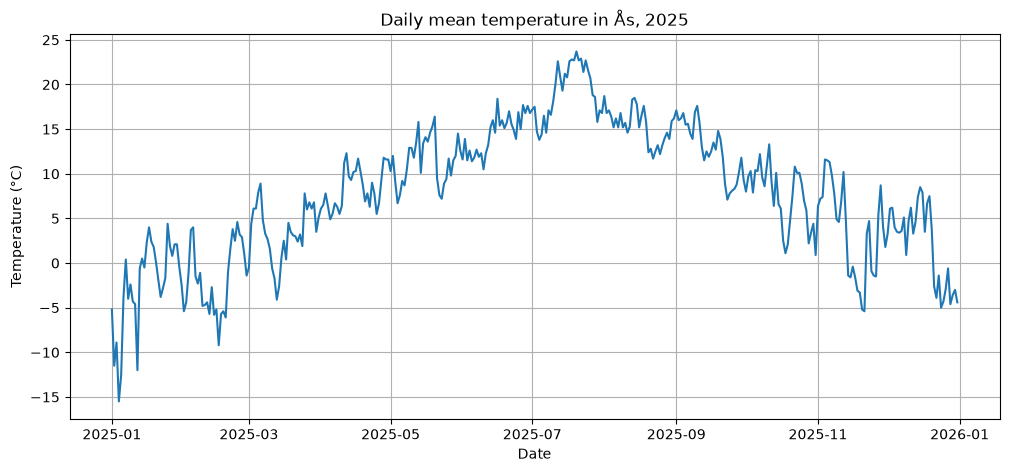

In [ ]:
# Oppretter en figur for å visualisere døgnmiddeltemperaturene gjennom året
plt.figure(figsize=(12, 5))

# Plotter døgnmiddeltemperaturene som en sammenhengende linje
plt.plot(df["date"], df["temperature"])

# Legger til aksetitler og en beskrivende figurtittel
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily mean temperature in Ås, 2025")

# Legger til rutenett for å gjøre grafen lettere å lese
plt.grid(True)

plt.show()

## Task 5

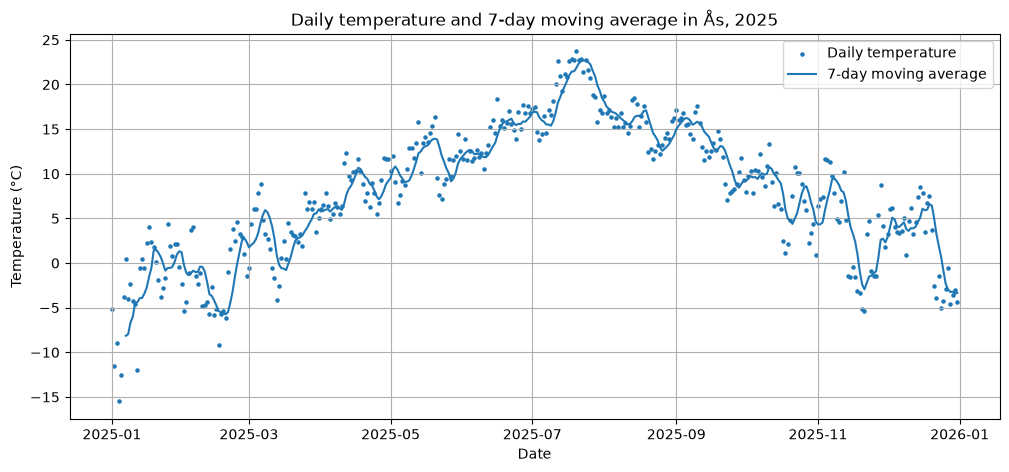

In [ ]:
# Funksjon som beregner 7-dagers glidende gjennomsnitt
def moving_average(temperatures: pd.Series) -> pd.Series:
    """Calculate the 7-day moving average of daily temperatures."""

    average = temperatures.rolling(window=7).mean()

    return average


# Bruker funksjonen på døgnmiddeltemperaturene fra Task 1
# og lagrer resultatet i en ny kolonne i DataFramen
df["moving_average"] = moving_average(df["temperature"])


# Oppretter en figur for å sammenligne daglige temperaturer og glidende gjennomsnitt
plt.figure(figsize=(12, 5))

# Viser de daglige temperaturene som punkter
plt.scatter(df["date"], df["temperature"], s=5, label="Daily temperature")

# Viser 7-dagers glidende gjennomsnitt som en sammenhengende linje
plt.plot(df["date"], df["moving_average"], label="7-day moving average")

# Legger til aksetitler, figurtittel, tegnforklaring og rutenett
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily temperature and 7-day moving average in Ås, 2025")
plt.legend()
plt.grid(True)
plt.show()
